In [34]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)

In [19]:
PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
TFIDF_MODEL_DIR = MODELS_DIR / "tfidf"

In [21]:
vectorizer = joblib.load(
    TFIDF_MODEL_DIR / "tfidf_vectorizer.joblib"
)


train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print(train.shape, validation.shape, test.shape)

(58823, 6) (12611, 6) (12632, 6)


In [22]:
X_train = vectorizer.transform(train["text"].astype(str))
X_val = vectorizer.transform(validation["text"].astype(str))
X_test = vectorizer.transform(test["text"].astype(str))

y_train = train["target"].astype(int)
y_val = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (58823, 100000)
Validation: (12611, 100000)
Test: (12632, 100000)


In [25]:
class SparseBatchGenerator(keras.utils.Sequence):
    def __init__(self, X, y, batch_size=128, shuffle=True):
        super().__init__()
        self.X = X
        self.y = np.asarray(y, dtype=np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(X.shape[0])
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = min((index + 1) * self.batch_size, len(self.indices))

        batch_indices = self.indices[start:end]

        X_batch = self.X[batch_indices].toarray().astype(np.float32)
        y_batch = self.y[batch_indices]

        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [46]:
BATCH_SIZE = 128

train_gen = SparseBatchGenerator(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_gen = SparseBatchGenerator(
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen = SparseBatchGenerator(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [27]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

In [28]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),

    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │     6,400,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,402,177 (24.42 MB)

 Trainable params: 6,402,177 (24.42 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.compile(
    optimizer=keras.optimizers.Adam(
    learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
    "accuracy",
    keras.metrics.AUC(name="auc")
]
)

In [32]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [33]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=[early_stopping],
    verbose=2
)

Epoch 1/20
460/460 - 8s - 16ms/step - accuracy: 0.8227 - auc: 0.8979 - loss: 0.5114 - val_accuracy: 0.9435 - val_auc: 0.9926 - val_loss: 0.2758
Epoch 2/20
460/460 - 7s - 15ms/step - accuracy: 0.9688 - auc: 0.9951 - loss: 0.1741 - val_accuracy: 0.9795 - val_auc: 0.9982 - val_loss: 0.0984
Epoch 3/20
460/460 - 7s - 15ms/step - accuracy: 0.9877 - auc: 0.9989 - loss: 0.0728 - val_accuracy: 0.9860 - val_auc: 0.9989 - val_loss: 0.0569
Epoch 4/20
460/460 - 7s - 15ms/step - accuracy: 0.9926 - auc: 0.9995 - loss: 0.0410 - val_accuracy: 0.9883 - val_auc: 0.9990 - val_loss: 0.0425
Epoch 5/20
460/460 - 7s - 15ms/step - accuracy: 0.9965 - auc: 0.9998 - loss: 0.0250 - val_accuracy: 0.9889 - val_auc: 0.9991 - val_loss: 0.0359
Epoch 6/20
460/460 - 7s - 14ms/step - accuracy: 0.9979 - auc: 0.9999 - loss: 0.0163 - val_accuracy: 0.9895 - val_auc: 0.9990 - val_loss: 0.0327
Epoch 7/20
460/460 - 7s - 14ms/step - accuracy: 0.9988 - auc: 1.0000 - loss: 0.0110 - val_accuracy: 0.9900 - val_auc: 0.9990 - val_loss:

### Evaluate on validation data

In [37]:
val_probs = model.predict(val_gen, verbose=0).ravel()

val_preds = (val_probs >= 0.5).astype(int)

In [42]:
fpr, tpr, thresholds = roc_curve(y_val, val_probs)
val_roc_auc = roc_auc_score(y_val, val_probs)

print(f"Validation Accuracy: {accuracy_score(y_val, val_preds):.4f}")

print(f"Validation Macro Precision: {precision_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation Macro Recall: {recall_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation Macro F1: {f1_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation ROC-AUC: {val_roc_auc:.4f}")

print("\nConfusion Matrix:\n",
    confusion_matrix(y_val,val_preds,),
)

Validation Accuracy: 0.9899
Validation Macro Precision: 0.9900
Validation Macro Recall: 0.9868
Validation Macro F1: 0.9884
Validation ROC-AUC: 0.9993

Confusion Matrix:
 [[8539   39]
 [  88 3945]]


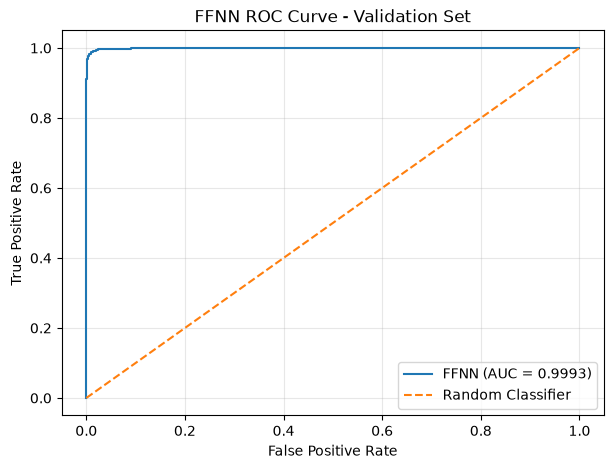

In [40]:
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"FFNN (AUC = {val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FFNN ROC Curve - Validation Set")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

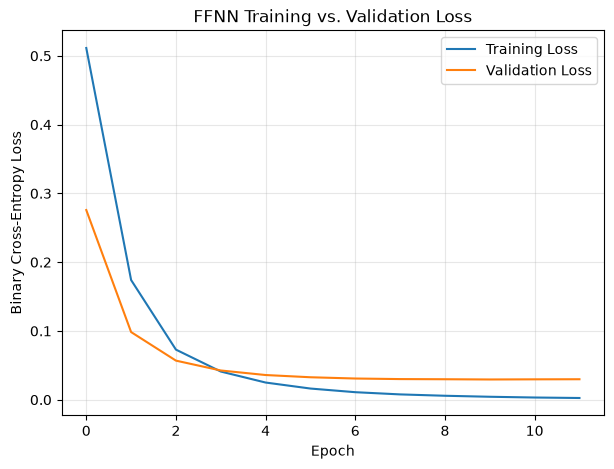

In [43]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("FFNN Training vs. Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

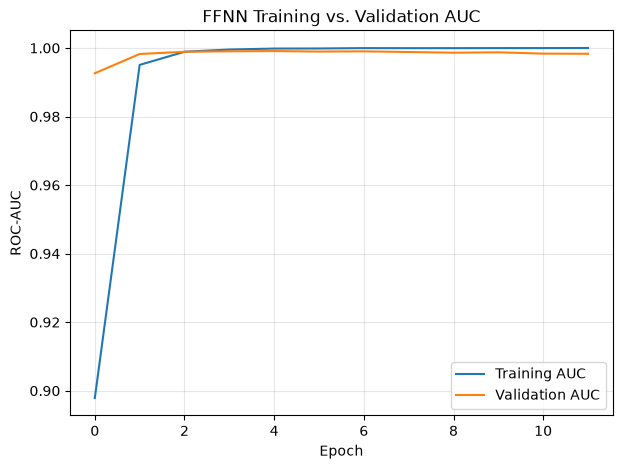

In [44]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("FFNN Training vs. Validation AUC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Evaluate on the test set

In [47]:
test_probs = model.predict(
    test_gen,
    verbose=0,
).ravel()

test_preds = (
    test_probs >= 0.5
).astype(int)

print(
    f"Test Accuracy:        "
    f"{accuracy_score(y_test, test_preds):.4f}"
)
print(
    f"Test Macro Precision: "
    f"{precision_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test Macro Recall:    "
    f"{recall_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test Macro F1:        "
    f"{f1_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test ROC-AUC:         "
    f"{roc_auc_score(y_test, test_probs):.4f}"
)

print(
    "\n"
    + classification_report(
        y_test,
        test_preds,
        target_names=[
            "Human",
            "ChatGPT",
        ],
        zero_division=0,
    )
)

Test Accuracy:        0.9896
Test Macro Precision: 0.9892
Test Macro Recall:    0.9870
Test Macro F1:        0.9881
Test ROC-AUC:         0.9994

              precision    recall  f1-score   support

       Human       0.99      0.99      0.99      8579
     ChatGPT       0.99      0.98      0.98      4053

    accuracy                           0.99     12632
   macro avg       0.99      0.99      0.99     12632
weighted avg       0.99      0.99      0.99     12632



### Save the neural network

In [49]:
model_path = (
    TFIDF_MODEL_DIR
    / "feedforward_neural_network.keras"
)

metadata_path = (
    TFIDF_MODEL_DIR
    / "feedforward_neural_network_metadata.json"
)

model.save(model_path)

metadata = {
    "threshold": 0.5,
    "vectorizer": "tfidf_vectorizer.joblib",
    "learning_rate": 0.0001,
    "batch_size": BATCH_SIZE,
    "architecture": [64, 32, 1],
}

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
    )

print(f"Saved neural network to {model_path}")
print(f"Saved metadata to {metadata_path}")

Saved neural network to ../models/tfidf/feedforward_neural_network.keras
Saved metadata to ../models/tfidf/feedforward_neural_network_metadata.json
